# Classification Models

## Discussion questions

Suppose you are developing a classification model to determine whether or not a person has a particular disease (based on symptoms, results of diagnostic tests, family history, risk factors, etc).

1. Explain what "precision" represents in this context.

Precision is the percentage of people predicted to have the disease who actually have it.

2. Explain what "recall" represents in this context.

Recall is the percentage of people who actually have the disease who are correctly predicted to have it.

3. Which of the following do you think is a more serious error? It's an opinion question, but choose one and discuss.

- Concluding that a person has the disease if they actually don't have it
- Failing to conclude that a person has the disease if they actually do have it

I think failing to identify someone who actually has the disease is more serious because they may not get the treatment they need, and their condition could get worse.

4. Given your answer to the previous question, which would you prefer to be higher: precision or recall?

I would prefer higher recall because I want to identify as many people who actually have the disease as possible.

5. Suppose you want to achieve higher recall. Should your classification rule be more or less strict about who it predicts to have the disease?

The rule should be less strict about predicting that someone has the disease. Lowering the probability threshold identifies more people with the disease and increases or maintains recall.

6. What is a downside to your choice in the previous part?

The model could incorrectly predict that more healthy people have the disease. These false positives could cause stress and unnecessary testing, and precision may decrease.

In [1]:
import pandas as pd
import numpy as np

## More wine

The wines data set (https://dlsun.github.io/pods/data/wines.csv ) contains data about the chemical composition of various wines. We'll first use just two features&mdash;fixed acidity and volatile acidity&mdash;to predict the color of the wine (red or white).

In [2]:
df_train = pd.read_csv("https://dlsun.github.io/pods/data/wines.csv")

df_train

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,red
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,white
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,white
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,white
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,white


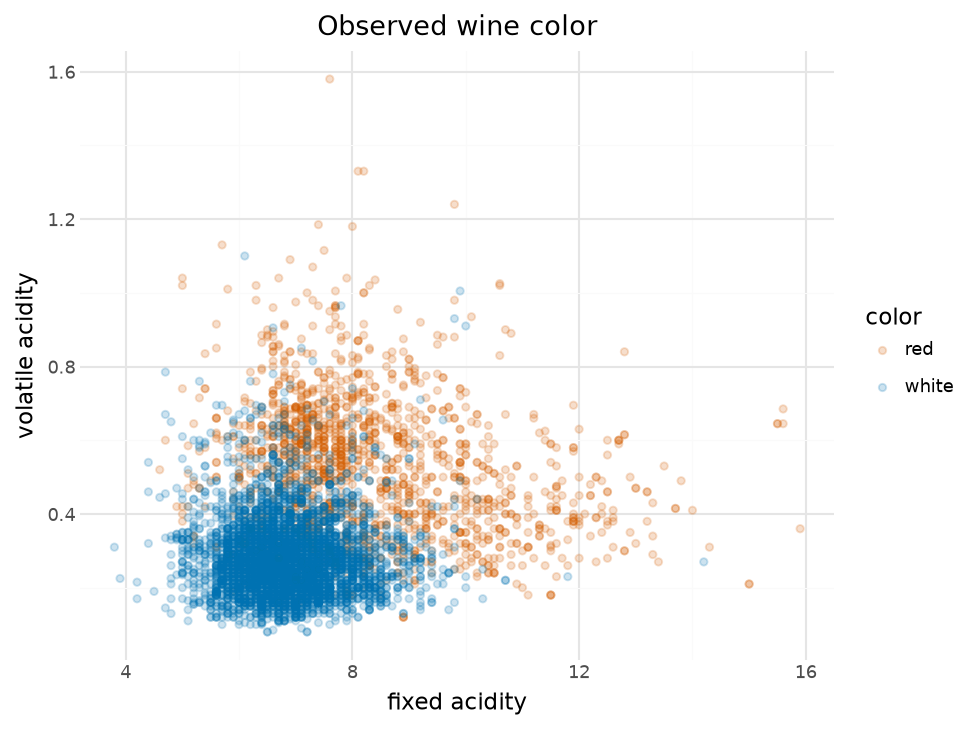

In [3]:
from plotnine import *

(
    ggplot(df_train, aes(x="fixed acidity", y="volatile acidity", color="color"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Observed wine color")
    + theme_minimal()
)

1\. Fit a 15-nearest neighbors model for predicting color from fixed acidity and volatile acidity. Don't forget to scale the features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the observed colors.

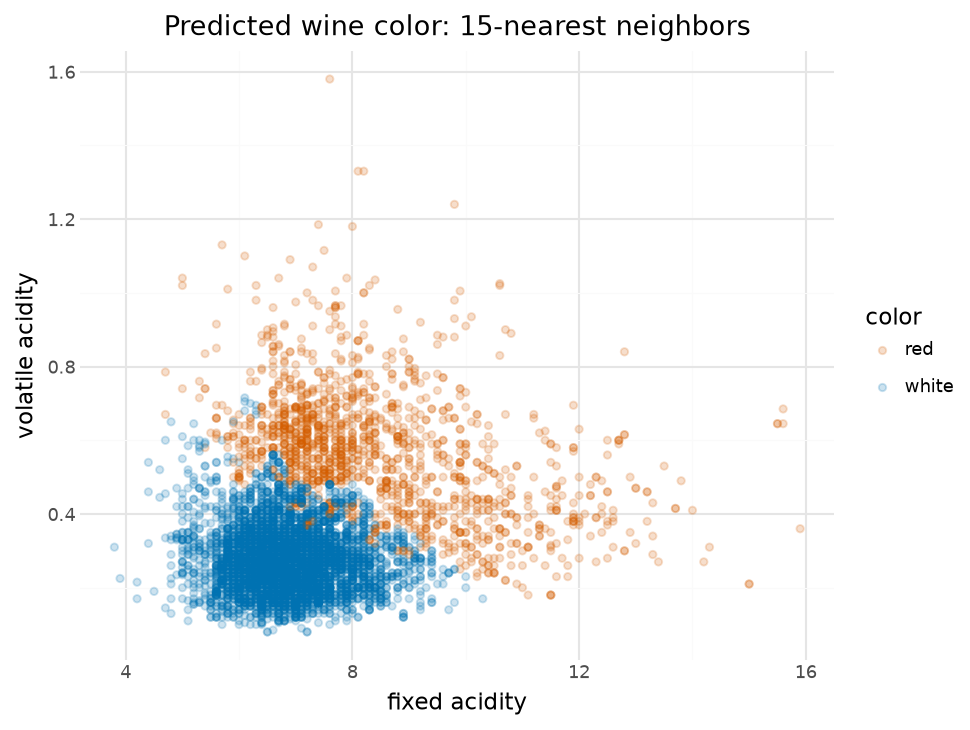

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

X = df_train[["fixed acidity", "volatile acidity"]]
y = df_train["color"]

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=15))
])

knn_model.fit(X, y)

df_predictions = df_train.copy()
df_predictions["knn_prediction"] = knn_model.predict(X)

(
    ggplot(df_predictions, aes(x="fixed acidity", y="volatile acidity", color="knn_prediction"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color: 15-nearest neighbors", color="color")
    + theme_minimal()
)

The predicted plot assigns colors based on the majority of the 15 nearest neighbors. It should show clearer regions than the observed plot, while individual wines in areas where the colors overlap can be misclassified.

2\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score using `macro` scoring.

In [5]:
from sklearn.model_selection import cross_validate

scoring = ["precision_macro", "recall_macro", "f1_macro"]

knn_cv = cross_validate(knn_model, X, y, cv=10, scoring=scoring)

knn_scores = pd.Series({
    "Precision": knn_cv["test_precision_macro"].mean(),
    "Recall": knn_cv["test_recall_macro"].mean(),
    "F1": knn_cv["test_f1_macro"].mean()
})

knn_scores

Precision    0.882173
Recall       0.855300
F1           0.864308
dtype: float64

Macro scoring calculates the score separately for red and white wines and averages the two, giving both colors equal weight. The reported values are the means across the 10 validation folds.

3\. Use `GridSearchCV` to fit $k$-nearest neighbors models for $k=1,\ldots, 30$ and use cross validation to estimate the test F1 macro score. Plot the test score versus $k$. Which value of $k$ yields the best score?

Best k: 16
Best estimated test F1 macro score: 0.8672105861720147


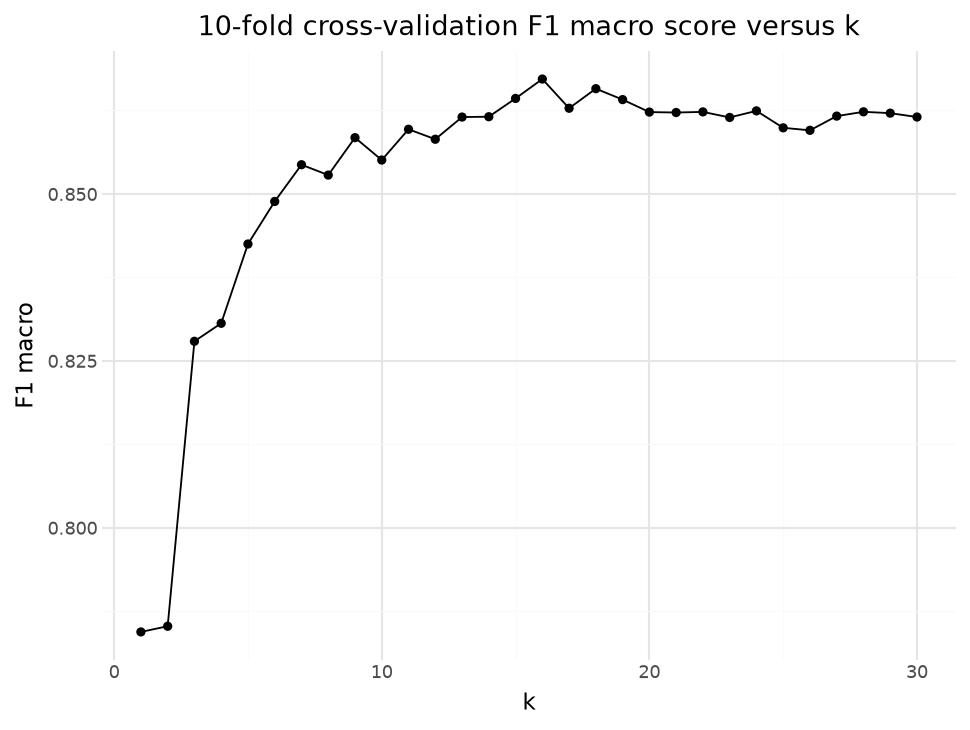

In [6]:
from sklearn.model_selection import GridSearchCV

knn_grid = GridSearchCV(
    knn_model,
    param_grid={"knn__n_neighbors": range(1, 31)},
    cv=10,
    scoring="f1_macro"
)

knn_grid.fit(X, y)

knn_results = pd.DataFrame({
    "k": knn_grid.cv_results_["param_knn__n_neighbors"].astype(int),
    "F1 macro": knn_grid.cv_results_["mean_test_score"]
})

print("Best k:", knn_grid.best_params_["knn__n_neighbors"])
print("Best estimated test F1 macro score:", knn_grid.best_score_)

(
    ggplot(knn_results, aes(x="k", y="F1 macro"))
    + geom_line()
    + geom_point()
    + labs(title="10-fold cross-validation F1 macro score versus k")
    + theme_minimal()
)

4\. When the target variable is binary **logistic regression** provides another classification algorithm.

Fit a logistic regression model for predicting wine color from the two features. Create a scatter plot of the predicted wine colors for the training data, and compare visually to the predictions from the nearest neighbors classifier.

Note: with regression, you don't need to scale the features (unless you add a penalty). Hint: you basically just need to replace with `KNeighborsClassifier()` with `LogisticRegression()`.

C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.


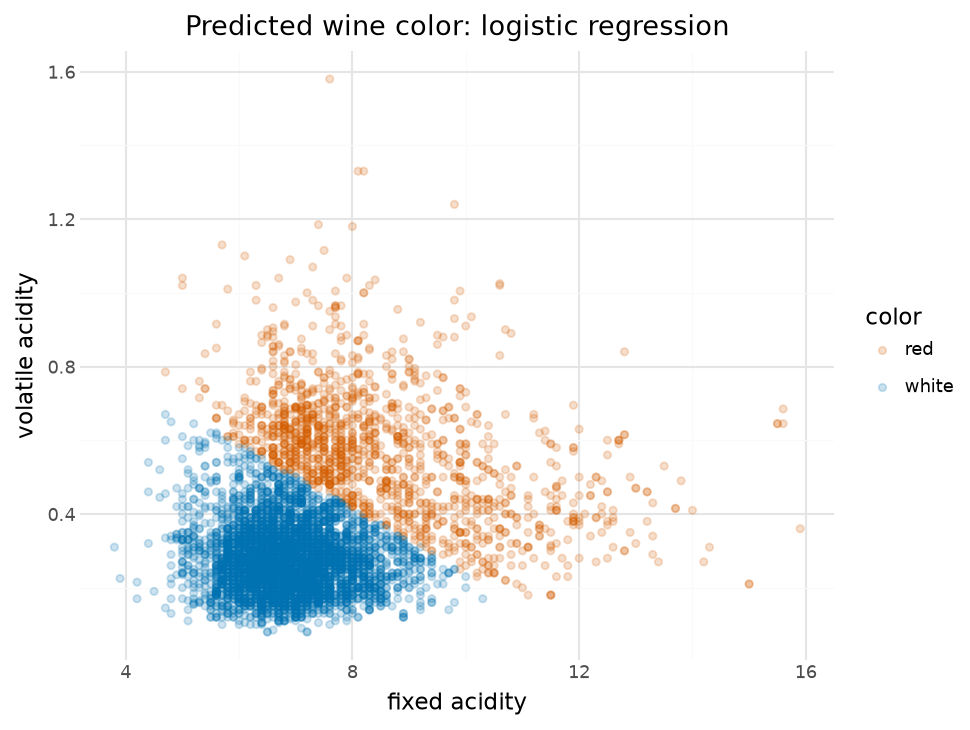

In [7]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(penalty=None, max_iter=10000)
logistic_model.fit(X, y)

df_predictions["logistic_prediction"] = logistic_model.predict(X)

(
    ggplot(df_predictions, aes(x="fixed acidity", y="volatile acidity", color="logistic_prediction"))
    + geom_point(alpha=0.2)
    + scale_color_manual(values={"red": "#D55E00", "white": "#0072B2"})
    + labs(title="Predicted wine color: logistic regression", color="color")
    + theme_minimal()
)

Logistic regression has a straight decision boundary with these two features. The nearest neighbors model can follow a more irregular boundary because its predictions depend on nearby wines.

5\. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring. Compare to the nearest neighbors model.

In [8]:
logistic_cv = cross_validate(logistic_model, X, y, cv=10, scoring=scoring)

logistic_scores = pd.Series({
    "Precision": logistic_cv["test_precision_macro"].mean(),
    "Recall": logistic_cv["test_recall_macro"].mean(),
    "F1": logistic_cv["test_f1_macro"].mean()
})

comparison = pd.DataFrame({
    "15-nearest neighbors": knn_scores,
    "Logistic regression": logistic_scores
})

for metric in comparison.index:
    difference = logistic_scores[metric] - knn_scores[metric]
    print(f"Logistic regression minus 15-nearest neighbors for {metric}: {difference:.4f}.")

print("Model with the higher estimated test F1 macro score:", comparison.loc["F1"].idxmax())
comparison

C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarni

Logistic regression minus 15-nearest neighbors for Precision: 0.0095.
Logistic regression minus 15-nearest neighbors for Recall: -0.0031.
Logistic regression minus 15-nearest neighbors for F1: 0.0003.
Model with the higher estimated test F1 macro score: Logistic regression


C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.


,15-nearest neighbors,Logistic regression
Precision,0.882173,0.891696
Recall,0.855300,0.852187
F1,0.864308,0.864589


A positive difference means logistic regression has the higher score; a negative difference means 15-nearest neighbors has the higher score. Higher precision means more accurate predictions within each color, and higher recall means finding a larger share of each actual color. F1 combines precision and recall.

6\. Now fit a logistic regression model using all of the potential predictors. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [9]:
X_all = df_train.drop(columns="color")

logistic_all = LogisticRegression(penalty=None, max_iter=10000)
logistic_all.fit(X_all, y)

logistic_all_cv = cross_validate(logistic_all, X_all, y, cv=10, scoring=scoring)

logistic_all_scores = pd.Series({
    "Precision": logistic_all_cv["test_precision_macro"].mean(),
    "Recall": logistic_all_cv["test_recall_macro"].mean(),
    "F1": logistic_all_cv["test_f1_macro"].mean()
})

logistic_all_scores

C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarni

Precision    0.985618
Recall       0.981608
F1           0.983514
dtype: float64

7\. Now fit a logistic regression model using all of the potential predictors with a LASSO (`"l1"`) penalty. Use 10-fold cross-validation to estimate the test precision, recall, and F1 score of the logistic regression model using `macro` scoring.

In [10]:
logistic_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(penalty="l1", solver="liblinear", max_iter=10000))
])

logistic_lasso.fit(X_all, y)

lasso_cv = cross_validate(logistic_lasso, X_all, y, cv=10, scoring=scoring)

lasso_scores = pd.Series({
    "Precision": lasso_cv["test_precision_macro"].mean(),
    "Recall": lasso_cv["test_recall_macro"].mean(),
    "F1": lasso_cv["test_f1_macro"].mean()
})

lasso_scores

C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
C:\Users\alexa\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio 

Precision    0.992155
Recall       0.990449
F1           0.991268
dtype: float64